# Deliverable 2: how well does the search work?

Author: Sarthak Aggarwal (MT26139) , Divyanshu Joshi (MT26120)

**Question.** The search should find the right ingredient whatever the user types: an exact name, a Hindi word, a different spelling, or a typo. How often does it get it right, where does it fail, and how fast is it?

**Method.** `D2_8_evaluate.py` ran every query in `D2_7_test_queries.csv` through the search and saved one row per query. This notebook reads those rows and draws the charts. Two steps (the cut-off test in Step 3 and the speed test in Step 5) run the search again.

**How to read the numbers.**
* *hit@1*: the right ingredient is the first result. *hit@5*: it is somewhere in the top 5.
* Queries that should find nothing (`no_match`) are counted on their own. Success there means an empty result.
* Rows marked `needs_review = yes` have answers written by hand, so their numbers depend on a person having checked them.

Files needed in the same folder: the `D2_*.py` files, `D2_7_test_queries.csv`, `D2_8_evaluation_results.csv`, `D1_input_lookup_ingredient_250_final_dataset.csv` and `D1_input_make_test_queries_26_Assignment_3_raw_input.csv`. Packages: pandas and matplotlib. Run All takes a few minutes, because Steps 3 and 5 run the search again.

In [1]:
import csv
import os
import tempfile
import time

import pandas as pd
import matplotlib.pyplot as plt

import D2_5_search as search_module
from D2_1_normalize import normalize
from D2_5_search import IngredientSearch

RESULTS = "D2_8_evaluation_results.csv"
QUERIES = "D2_7_test_queries.csv"
RECIPES = "D1_input_make_test_queries_26_Assignment_3_raw_input.csv"

BLUE, ORANGE = "#2a78d6", "#eb6834"                      # chart colours
INK, SOFT, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

def percent(ax, axis="y"):
    """Show an axis as 0% to 100%."""
    fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

res = pd.read_csv(RESULTS, encoding="utf-8-sig")
real = res[res["query_type"] != "no_match"].copy()       # queries that have a correct answer
nomatch = res[res["query_type"] == "no_match"].copy()    # queries that should return nothing
real["rr"] = (1 / real["rank_of_correct"]).where(real["rank_of_correct"] > 0, 0)   # 1/rank, 0 if missed

TYPE_ORDER = ["english_exact", "roman_exact", "hindi_exact", "hindi_nukta", "format_noise",
              "prefix", "typo_1", "typo_2", "hindi_typo", "alt_spelling", "recipe_phrase"]
print(len(res), "queries:", len(real), "have an answer,", len(nomatch), "should find nothing")

389 queries: 364 have an answer, 25 should find nothing


## Step 1. Accuracy by type of query
Each bar is the share of queries of that type answered correctly. Blue is the strict test (the right ingredient comes first), orange is the loose one (it appears in the top 5). The gap between them is the cases where the right ingredient was found but ranked lower.

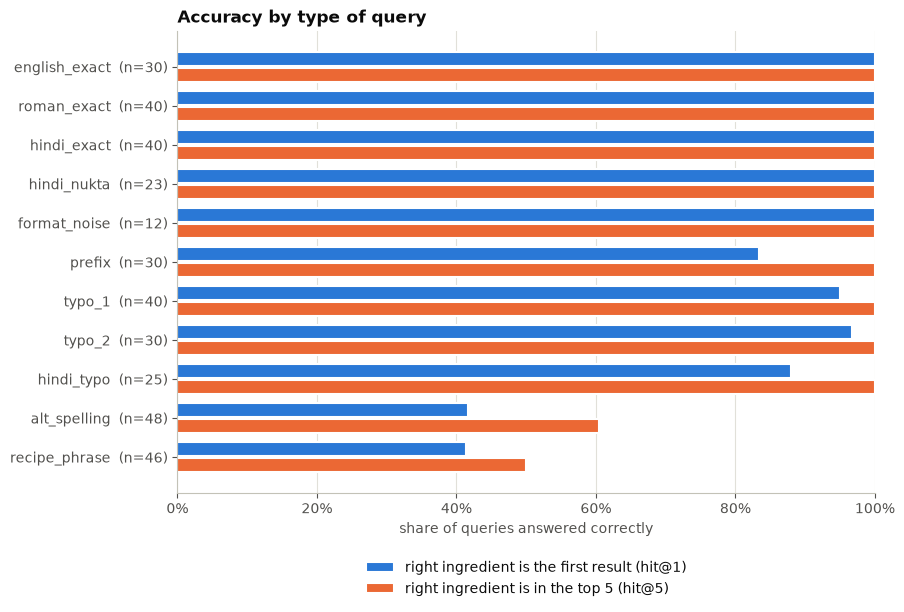

,n,hit1,hit3,hit5,mrr
query_type,,,,,
english_exact,30,1.00,1.00,1.0,1.00
roman_exact,40,1.00,1.00,1.0,1.00
hindi_exact,40,1.00,1.00,1.0,1.00
hindi_nukta,23,1.00,1.00,1.0,1.00
format_noise,12,1.00,1.00,1.0,1.00
prefix,30,0.83,1.00,1.0,0.91
typo_1,40,0.95,1.00,1.0,0.98
typo_2,30,0.97,1.00,1.0,0.98
hindi_typo,25,0.88,1.00,1.0,0.94


In [2]:
by_type = real.groupby("query_type").agg(n=("query_id", "count"), hit1=("hit1", "mean"),
                                         hit3=("hit3", "mean"), hit5=("hit5", "mean"), mrr=("rr", "mean"))
by_type = by_type.reindex([t for t in TYPE_ORDER if t in by_type.index])

fig, ax = plt.subplots(figsize=(9, 6))
y = list(range(len(by_type)))
ax.barh([i - 0.2 for i in y], by_type["hit1"], height=0.36, color=BLUE, edgecolor="white", linewidth=1.5,
        label="right ingredient is the first result (hit@1)")
ax.barh([i + 0.2 for i in y], by_type["hit5"], height=0.36, color=ORANGE, edgecolor="white", linewidth=1.5,
        label="right ingredient is in the top 5 (hit@5)")
ax.set_yticks(y)
ax.set_yticklabels([f"{t}  (n={n})" for t, n in zip(by_type.index, by_type["n"])])
ax.invert_yaxis()
ax.set_xlim(0, 1)
percent(ax, "x")
ax.grid(axis="x")
ax.set_xlabel("share of queries answered correctly")
ax.set_title("Accuracy by type of query")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.savefig("D2_9_accuracy_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

by_type.round(2)

In [3]:
# Queries that should find nothing, and how the hand-written rows compare with the rest
rejected = nomatch["rejected"].mean()
print(f"{len(nomatch)} queries should find nothing; the search returned nothing for {rejected:.0%} of them.")
print("Wrongly matched:")
print(nomatch.loc[nomatch["rejected"] == 0, ["query", "top3"]].to_string(index=False))

print("\nAccuracy for rows with and without hand-written answers (needs_review):")
real.groupby("needs_review")[["hit1", "hit5"]].agg(["count", "mean"]).round(2)

25 queries should find nothing; the search returned nothing for 96% of them.
Wrongly matched:
  query                                                                       top3
paprika papaya (0.43, fuzzy); papaya paste (0.43, fuzzy); raw papaya (0.43, fuzzy)

Accuracy for rows with and without hand-written answers (needs_review):


hit1        hit5      
             count  mean count  mean
needs_review                        
no             309  0.96   309  1.00
yes             55  0.00    55  0.24

## Step 2. Accuracy against edit distance
For every query, how many single-letter changes separate it from the nearest correct name? Distance 0 is an exact name. The search compares the whole query with whole names, so a longer phrase such as `lemon juice` counts as far from `lemon` even though one word matches. Keep that in mind when reading the right-hand bars.

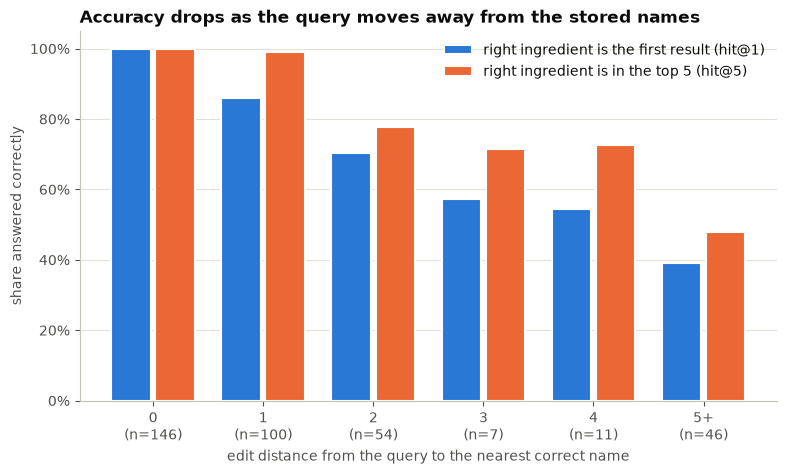

,n,hit1,hit5
distance,,,
0,146,1.00,1.00
1,100,0.86,0.99
2,54,0.70,0.78
3,7,0.57,0.71
4,11,0.55,0.73
5,46,0.39,0.48


In [4]:
real["distance"] = real["edit_distance"].clip(upper=5).astype(int)      # 5 means "5 or more"
by_dist = real.groupby("distance").agg(n=("query_id", "count"), hit1=("hit1", "mean"), hit5=("hit5", "mean"))

fig, ax = plt.subplots(figsize=(9, 4.8))
x = list(range(len(by_dist)))
ax.bar([i - 0.2 for i in x], by_dist["hit1"], width=0.36, color=BLUE, edgecolor="white", linewidth=1.5,
       label="right ingredient is the first result (hit@1)")
ax.bar([i + 0.2 for i in x], by_dist["hit5"], width=0.36, color=ORANGE, edgecolor="white", linewidth=1.5,
       label="right ingredient is in the top 5 (hit@5)")
ax.set_xticks(x)
ax.set_xticklabels([f"{d if d < 5 else '5+'}\n(n={n})" for d, n in zip(by_dist.index, by_dist["n"])])
ax.set_ylim(0, 1.05)
percent(ax, "y")
ax.grid(axis="y")
ax.set_xlabel("edit distance from the query to the nearest correct name")
ax.set_ylabel("share answered correctly")
ax.set_title("Accuracy drops as the query moves away from the stored names")
ax.legend(loc="upper right", frameon=False)
plt.savefig("D2_9_accuracy_by_distance.png", dpi=150, bbox_inches="tight")
plt.show()

by_dist.round(2)

## Step 3. Where should the fuzzy cut-off be?
A fuzzy match is kept only if its similarity (1 minus edit distance divided by the longer length) is at least the cut-off. A low cut-off finds more real spellings but also lets in wrong ingredients. A high one is safer but misses spellings.

We run the whole test set again at five cut-offs. Blue is how often the right ingredient is in the top 5. Orange is how often a query that should find nothing still got a result (a false match). The project uses 0.7. This step takes a couple of minutes.

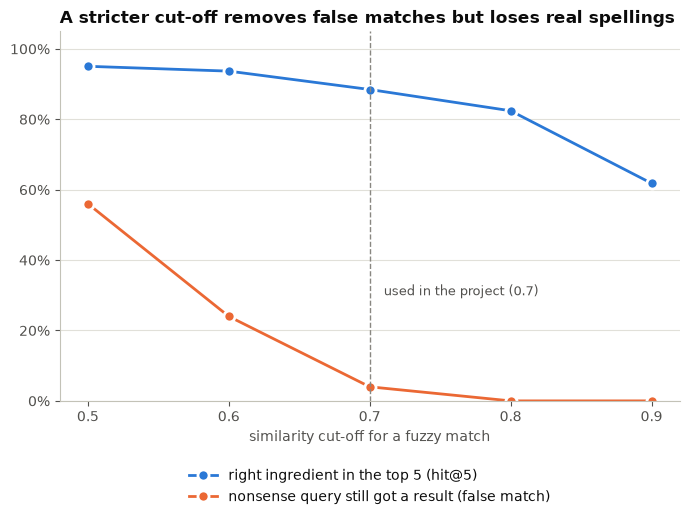

,cutoff,hit1,hit5,false_match
0,0.5,0.846,0.951,0.56
1,0.6,0.841,0.937,0.24
2,0.7,0.819,0.885,0.04
3,0.8,0.783,0.824,0.00
4,0.9,0.604,0.618,0.00


In [5]:
queries = pd.read_csv(QUERIES, encoding="utf-8-sig", dtype=str, keep_default_na=False)
engine = IngredientSearch()
USED_CUTOFF = search_module.MIN_SIMILARITY

def run_all(cutoff):
    search_module.MIN_SIMILARITY = cutoff           # the search reads this value on every call
    n = first = top5 = n_none = false_match = 0
    for _, row in queries.iterrows():
        correct = {int(i) for i in row["correct_indexes"].split("|") if i}
        shown = [m["index"] for m in engine.search(row["query"], top_k=5)]
        if not correct:
            n_none += 1
            false_match += bool(shown)
            continue
        n += 1
        first += bool(shown) and shown[0] in correct
        top5 += any(i in correct for i in shown)
    return {"cutoff": cutoff, "hit1": first / n, "hit5": top5 / n, "false_match": false_match / n_none}

sweep = pd.DataFrame([run_all(c) for c in (0.5, 0.6, 0.7, 0.8, 0.9)])
search_module.MIN_SIMILARITY = USED_CUTOFF          # put the project value back

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(sweep["cutoff"], sweep["hit5"], color=BLUE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="right ingredient in the top 5 (hit@5)")
ax.plot(sweep["cutoff"], sweep["false_match"], color=ORANGE, linewidth=2, marker="o", markersize=8,
        markeredgecolor="white", markeredgewidth=2, label="nonsense query still got a result (false match)")
ax.axvline(USED_CUTOFF, color=MUTED, linestyle="--", linewidth=1)
ax.text(USED_CUTOFF + 0.01, 0.3, f"used in the project ({USED_CUTOFF})", color=SOFT, fontsize=9)
ax.set_xticks(sweep["cutoff"])
ax.set_ylim(0, 1.05)
percent(ax, "y")
ax.grid(axis="y")
ax.set_xlabel("similarity cut-off for a fuzzy match")
ax.set_title("A stricter cut-off removes false matches but loses real spellings")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.savefig("D2_9_cutoff_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

sweep.round(3)

## Step 4. Where it fails
A query fails when the right ingredient is not in the top 5. There are two kinds: the search returned **nothing** (every name was too far away), or it returned **the wrong ingredient** (something looked closer). The table lists every failure, and it is also saved as `D2_9_failures.csv`.

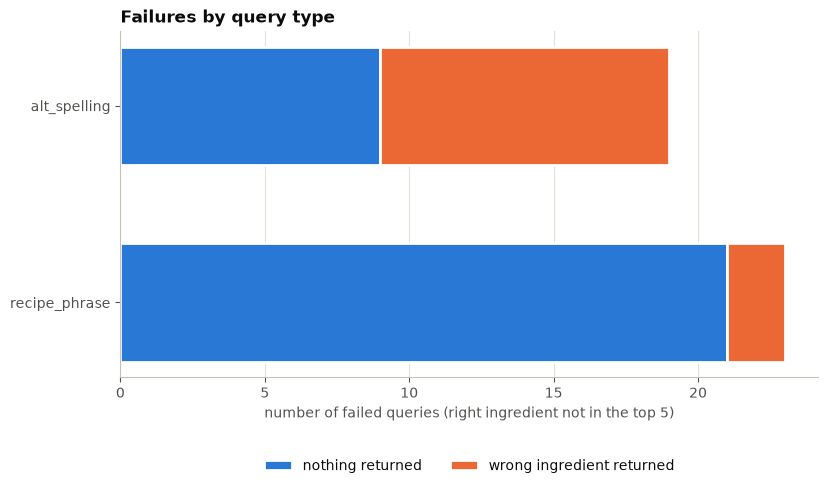

42 failed queries out of 364


,query_id,query,query_type,correct,top3,failure_type
0,Q271,jira,alt_spelling,cumin seeds,NaN,nothing returned
1,Q273,zira,alt_spelling,cumin seeds,NaN,nothing returned
2,Q274,lasan,alt_spelling,garlic,NaN,nothing returned
3,Q288,desi ghee,alt_spelling,ghee,NaN,nothing returned
4,Q291,lavang,alt_spelling,cloves,NaN,nothing returned
5,Q295,nimboo,alt_spelling,lemon,NaN,nothing returned
6,Q296,dahee,alt_spelling,curd,NaN,nothing returned
7,Q304,sonf,alt_spelling,fennel seeds|mouth-freshener fennel seeds,NaN,nothing returned
8,Q312,zafran,alt_spelling,saffron strands,NaN,nothing returned
9,Q321,ground black pepper,recipe_phrase,black pepper powder,NaN,nothing returned


In [6]:
fail = real[real["hit5"] == 0].copy()
fail["failure_type"] = fail["top1"].isna().map({True: "nothing returned", False: "wrong ingredient returned"})
KINDS = ["nothing returned", "wrong ingredient returned"]
counts = pd.crosstab(fail["query_type"], fail["failure_type"]).reindex(columns=KINDS, fill_value=0)
counts = counts.reindex([t for t in TYPE_ORDER if t in counts.index])

fig, ax = plt.subplots(figsize=(9, 4.5))
left = [0] * len(counts)
for kind, colour in zip(KINDS, (BLUE, ORANGE)):
    ax.barh(list(range(len(counts))), counts[kind], left=left, height=0.6, color=colour,
            edgecolor="white", linewidth=2, label=kind)
    left = [a + b for a, b in zip(left, counts[kind])]
ax.set_yticks(list(range(len(counts))))
ax.set_yticklabels(counts.index)
ax.invert_yaxis()
ax.grid(axis="x")
ax.set_xlabel("number of failed queries (right ingredient not in the top 5)")
ax.set_title("Failures by query type")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.savefig("D2_9_failures_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

table = fail[["query_id", "query", "query_type", "correct", "top3", "failure_type"]]
table = table.sort_values(["failure_type", "query_type", "query_id"]).reset_index(drop=True)
table.to_csv("D2_9_failures.csv", index=False, encoding="utf-8-sig")
print(len(table), "failed queries out of", len(real))
table

## Step 5. Speed
**Speed by type.** Exact lookups are a dictionary access, so they take a few hundredths of a millisecond. Anything that reaches the fuzzy step compares the query with every name, which takes tens of milliseconds. The axis is logarithmic so both can be seen.

**Speed as the list grows.** Our dataset has 250 ingredients. To see what happens with a bigger list, we load the roughly 5,000 different ingredient phrases from the 10,000 recipes as if they were ingredient names, and time the same searches. Times are from the computer that runs this notebook.

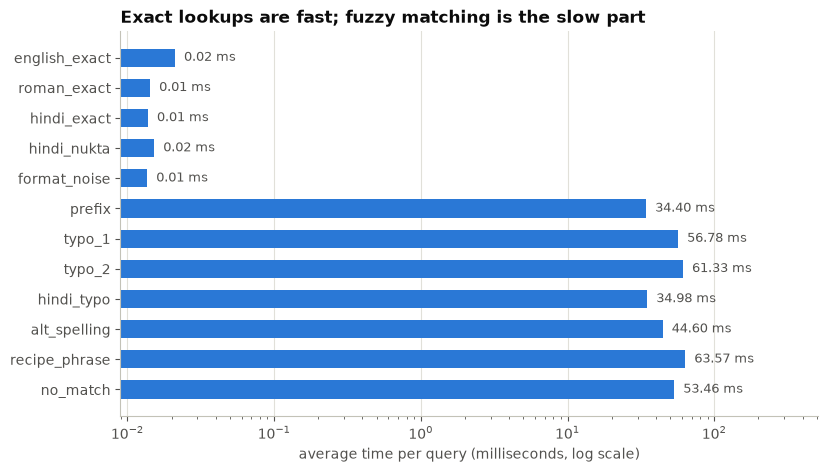

In [7]:
by_speed = res.groupby("query_type")["ms"].mean().reindex([t for t in TYPE_ORDER + ["no_match"] if t in set(res["query_type"])])

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(list(range(len(by_speed))), by_speed, height=0.6, color=BLUE)
ax.set_xscale("log")
ax.set_yticks(list(range(len(by_speed))))
ax.set_yticklabels(by_speed.index)
ax.invert_yaxis()
ax.grid(axis="x")
for i, v in enumerate(by_speed):
    ax.text(v * 1.15, i, f"{v:.2f} ms", va="center", fontsize=9, color=SOFT)
ax.set_xlim(right=by_speed.max() * 8)
ax.set_xlabel("average time per query (milliseconds, log scale)")
ax.set_title("Exact lookups are fast; fuzzy matching is the slow part")
plt.savefig("D2_9_speed_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

small list: 250 ingredients, 1135 names
big list:   5309 ingredients, 5309 names


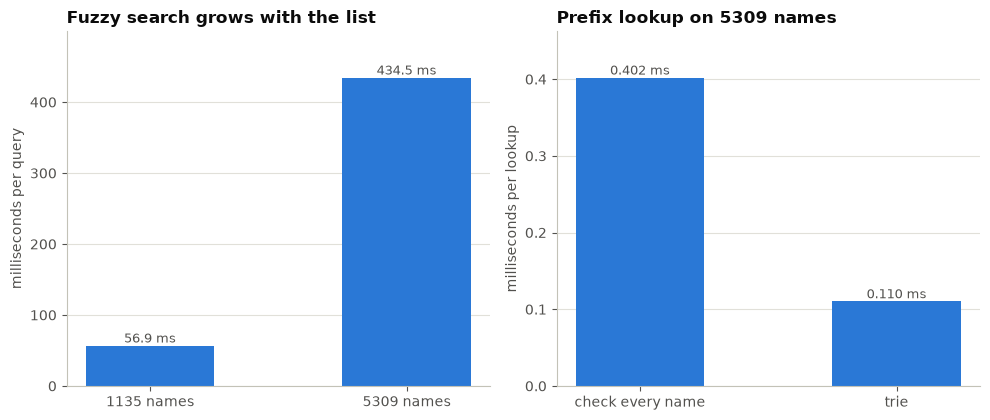

In [8]:
# A bigger list: every different ingredient phrase from the 10,000 recipes becomes one "ingredient"
phrases = set()
with open(RECIPES, encoding="utf-8-sig", newline="") as f:
    for row in csv.DictReader(f):
        text = row["Ingredients_List"].strip().strip("[]")
        phrases.update(p.strip().lower() for p in text.split(",") if p.strip())
phrases = sorted(phrases)

with tempfile.TemporaryDirectory() as folder:
    path = os.path.join(folder, "phrases.csv")
    with open(path, "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["english_name", "index", "roman_variants", "hindi_devanagari"])
        for i, phrase in enumerate(phrases, 1):
            writer.writerow([phrase, i, "", "not available"])
    big = IngredientSearch(path)
small = IngredientSearch()

names_small = sum(len(r["names"]) for r in small.ingredients.values())
names_big = sum(len(r["names"]) for r in big.ingredients.values())
print(f"small list: {len(small.ingredients)} ingredients, {names_small} names")
print(f"big list:   {len(big.ingredients)} ingredients, {names_big} names")

def mean_ms(engine, texts, repeats):
    start = time.perf_counter()
    for _ in range(repeats):
        for t in texts:
            engine.search(t)
    return (time.perf_counter() - start) / (repeats * len(texts)) * 1000

typos = res[res["query_type"] == "typo_1"]["query"].head(8).tolist()
fuzzy_small = mean_ms(small, typos, repeats=3)
fuzzy_big = mean_ms(big, typos, repeats=1)

# prefix lookup: the trie against checking every name one by one
prefixes = [normalize(q) for q in res[res["query_type"] == "prefix"]["query"]]
all_names = [(name, i) for i, rec in big.ingredients.items() for name in rec["names"]]

def per_call_ms(fn, repeats=20):
    start = time.perf_counter()
    for _ in range(repeats):
        for p in prefixes:
            fn(p)
    return (time.perf_counter() - start) / (repeats * len(prefixes)) * 1000

scan_ms = per_call_ms(lambda p: [x for x in all_names if x[0].startswith(p)])
trie_ms = per_call_ms(lambda p: big.trie.with_prefix(p))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.3))
left.bar([f"{names_small} names", f"{names_big} names"], [fuzzy_small, fuzzy_big], width=0.5, color=BLUE)
left.set_title("Fuzzy search grows with the list")
left.set_ylabel("milliseconds per query")
for i, v in enumerate([fuzzy_small, fuzzy_big]):
    left.text(i, v, f"{v:.1f} ms", ha="center", va="bottom", fontsize=9, color=SOFT)
left.set_ylim(0, max(fuzzy_small, fuzzy_big) * 1.15)
left.grid(axis="y")

right.bar(["check every name", "trie"], [scan_ms, trie_ms], width=0.5, color=BLUE)
right.set_title(f"Prefix lookup on {names_big} names")
right.set_ylabel("milliseconds per lookup")
for i, v in enumerate([scan_ms, trie_ms]):
    right.text(i, v, f"{v:.3f} ms", ha="center", va="bottom", fontsize=9, color=SOFT)
right.set_ylim(0, max(scan_ms, trie_ms) * 1.15)
right.grid(axis="y")
plt.tight_layout()
plt.savefig("D2_9_speed_scaling.png", dpi=150, bbox_inches="tight")
plt.show()

## About the result
* **Exact names, Hindi names and formatting changes** (capitals, spaces, hyphens, the Hindi nukta) are found every time. They never reach the fuzzy step, so they are also the fastest.
* **Typos** are handled well. The right ingredient is almost always in the top 5, and usually first. Accuracy falls as the edit distance grows (Step 2).
* **Spellings that are not in the dataset, and recipe phrases, are the weak spot.** Step 4 shows why: either the spelling is too far from every stored name (nothing returned), or the query has extra words (`lemon juice`) and the search compares the whole phrase with whole names, not word by word.
* **The cut-off is a trade** (Step 3). A lower cut-off finds more spellings and lets in more wrong matches. We kept 0.7, which the chart lets us defend or change with evidence.
* **Speed.** Exact lookup and the trie are almost instant. The fuzzy step compares the query with every name, so its time grows with the list (Step 5). That is fine for 250 ingredients and would need a smarter index for a much larger list.
* **Limits of this test.** The typos were made by a script, not by real users. The answers for spellings and recipe phrases (`needs_review = yes`) were written by hand, so those two numbers are only as good as that checking. The recipe file is mostly English, so it says little about Hindi spellings.